Dataset Shape: (569, 30)

Features:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target Classes: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Baseline: Logistic Regression
Features: 30

Feature Selection
Selected Features: ['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']

Feature Engineering
Features before: 10
Features after: 65

Performance Comparison


,Model,Features,Accuracy,Precision,Recall,F1 Score
0,Baseline,30,0.9825,0.9861,0.9861,0.9861
1,Feature Selection,10,0.9474,0.9714,0.9444,0.9577
2,Feature Engineering,65,0.9649,0.9595,0.9861,0.9726


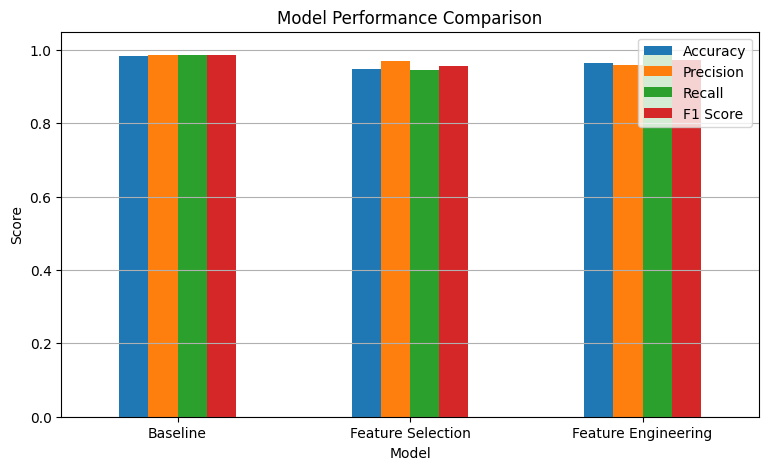

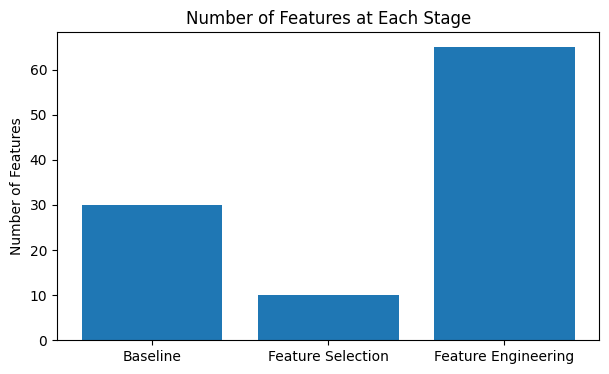

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Load Dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target
print("Dataset Shape:", X.shape)
print("\nFeatures:")
print(list(X.columns))
print("\nTarget Classes:", data.target_names)

# Show a small sample
display(X.head())

# 2. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Function to calculate metrics
def evaluate(model, Xtr, Xte):
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    return [
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred)]

# 4. Baseline Model
baseline = LogisticRegression(max_iter=5000)
baseline_scores = evaluate(baseline, X_train, X_test)
print("\nBaseline: Logistic Regression")
print("Features:", X.shape[1])

# 5. Feature Selection
selector = SelectKBest(f_classif, k=10)

X_train_sel = selector.fit_transform(X_train, y_train)
X_test_sel = selector.transform(X_test)

selected = X.columns[selector.get_support()]

print("\nFeature Selection")
print("Selected Features:", list(selected))

selection_model = LogisticRegression(max_iter=5000)
selection_scores = evaluate(selection_model, X_train_sel, X_test_sel)

# 6. Feature Engineering
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_eng = poly.fit_transform(X_train_sel)
X_test_eng = poly.transform(X_test_sel)

print("\nFeature Engineering")
print("Features before:", X_train_sel.shape[1])
print("Features after:", X_train_eng.shape[1])

engineering_model = LogisticRegression(max_iter=5000)
engineering_scores = evaluate(
    engineering_model, X_train_eng, X_test_eng
)

# 7. Comparison
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Feature Selection",
        "Feature Engineering"],
    "Features": [
        X.shape[1],
        X_train_sel.shape[1],
        X_train_eng.shape[1]],
    "Accuracy": [
        baseline_scores[0],
        selection_scores[0],
        engineering_scores[0]],
    "Precision": [
        baseline_scores[1],
        selection_scores[1],
        engineering_scores[1]],
    "Recall": [
        baseline_scores[2],
        selection_scores[2],
        engineering_scores[2]],
    "F1 Score": [
        baseline_scores[3],
        selection_scores[3],
        engineering_scores[3]]
})
print("\nPerformance Comparison")
display(results.round(4))

# 8. Performance Graph
results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(9, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

# 9. Feature Count Graph
plt.figure(figsize=(7, 4))

plt.bar(
    results["Model"],
    results["Features"]
)

plt.title("Number of Features at Each Stage")
plt.ylabel("Number of Features")
plt.xticks(rotation=0)
plt.show()